# A0. Bogotá station locations, digitised from Bustos et al. (2026), Fig. 1

The RMCAB network map in Bustos, Garcia, Rojas, Lopez-Barrera, Peña-Rincon & Casallas (2026,
*Earth Systems and Environment*, doi:10.1007/s41748-026-01052-3), Fig. 1, has a lat/lon graticule and
one coloured triangle per station. The coordinates themselves are in that paper's Supplementary
Table SM1, which we do not have, so **positions are digitised from the figure**:

1. extract the embedded map image from the PDF;
2. fit pixel -> lon/lat from the labelled graticule lines (residual < 1 px, about 26 m per pixel);
3. find each triangle by matching the legend colour, then take the centre of its bounding box;
4. two markers (Guaymaral, Fontibón) are partly hidden by a graticule line / a label and were placed by hand;
5. check the result visually on the overlay image written to `Paper/figures/data/reference/`.

Expect roughly ±100 m (marker anchor plus digitising). Replace `bogota_stations_digitised.csv` with the
supplementary-table coordinates when they are available; the map notebook only reads that CSV.
The extracted figure is used for provenance only and is not to be redistributed.

In [1]:
# Setup
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
sys.path.insert(0, str(HERE.parent)); sys.path.insert(0, str(HERE.parents[1]))
import json
import numpy as np, pandas as pd
from PIL import Image, ImageDraw
from scipy import ndimage as ndi
from style import ROOT, DATA_OUT
import fitz   # PyMuPDF

In [2]:
# Settings (edit here)
PDF = Path("/path/to/Amazon_org/Articles_mios/Bustos_Casallas_ozone.pdf")
PAGE = 3                                   # 0-based page holding Fig. 1
REF = DATA_OUT / "reference"; REF.mkdir(exist_ok=True)

# graticule lines: approximate pixel seeds and their labelled values
GRID_X_SEED = [181, 568, 956]; GRID_X_LON = [-(74 + 13/60), -(74 + 7.5/60), -(74 + 2/60)]      # 74d13'0"W, 74d7'30"W, 74d2'0"W
GRID_Y_SEED = [162, 547, 934, 1319]; GRID_Y_LAT = [4 + 47/60, 4 + 41.5/60, 4 + 36/60, 4 + 30.5/60]   # 4d47'0"N ... 4d30'30"N
MAP_BOX = (48, 46, 1338, 1420)             # x0, y0, x1, y1 of the map frame in the image (px)

# legend swatch positions (px in the embedded image): left column x, right column x, and y per station
LEGEND = {"Bolivia": (1450, 971), "Carvajal-Sevillana": (1450, 1008), "Centro de alto rendimiento": (1450, 1045),
          "Ciudad Bolívar": (1450, 1082), "Colina": (1450, 1118), "El Jazmín": (1450, 1155), "Fontibón": (1450, 1192),
          "Guaymaral": (1450, 1229),
          "Kennedy": (1799, 885), "Las Ferias": (1799, 923), "MinAmbiente": (1799, 959), "Móvil Fontibón": (1799, 997),
          "Puente Aranda": (1799, 1034), "San Cristóbal": (1799, 1070), "Suba": (1799, 1107), "Tunal": (1799, 1143),
          "Usaquén": (1799, 1180), "Usme": (1799, 1217)}
MANUAL_CENTRES = {"Guaymaral": (910.0, 160.5), "Fontibón": (488.0, 602.0)}   # partly hidden markers, placed by eye

# map from the paper's names to the names in our two data sources
NAME_MAP = {  # paper name: (SISAIRE PM2.5 name, hourly O3/NO/CO name)
    "Bolivia": ("BOLIVIA", "BOLIVIA"), "Carvajal-Sevillana": ("CARVAJAL - SEVILLANA", "CARVAJAL"),
    "Centro de alto rendimiento": ("CENTRO DE ALTO RENDIMIENTO", "CENTRO DE ALTO RENDIMIENTO"),
    "Ciudad Bolívar": ("CIUDAD BOLÍVAR", "CIUDAD BOLIVAR"), "Colina": ("COLINA", "COLINA"),
    "El Jazmín": ("EL JAZMÍN", "JAZMIN"),
    "Fontibón": ("P_CAMI - FONTIBÓN", "FONTIBON"),     # PROBABLE match (CAMI Fontibón = the RMCAB Fontibón station); to be confirmed
    "Guaymaral": ("GUAYMARAL", "GUAYMARAL"), "Kennedy": ("KENNEDY", "KENNEDY"), "Las Ferias": ("LAS FERIAS", "LAS FERIAS"),
    "MinAmbiente": ("MINAMBIENTE", "MIN AMBIENTE"), "Móvil Fontibón": ("MÓVIL FONTIBÓN", "MOVIL FONTIBON"),
    "Puente Aranda": ("PUENTE ARANDA", "PUENTE ARANDA"), "San Cristóbal": ("SAN CRISTOBAL", "SAN CRISTOBAL"),
    "Suba": ("SUBA", "SUBA"), "Tunal": ("TUNAL", "TUNAL"), "Usaquén": ("USAQUEN", "USAQUEN"), "Usme": ("USME", "USME")}

In [3]:
# 1. Extract the map image and fit pixel -> lon/lat from the graticule
doc = fitz.open(PDF)
img_info = max(doc[PAGE].get_images(full=True), key=lambda i: i[2] * i[3])
raw = doc.extract_image(img_info[0])
IMG_PATH = REF / "bustos2026_fig1_extracted.jpeg"; IMG_PATH.write_bytes(raw["image"])
img = Image.open(IMG_PATH).convert("RGB"); im = np.array(img).astype(float); gray = im.mean(axis=2)
x0, y0, x1, y1 = MAP_BOX
snap_v = lambda xa: min(range(xa - 14, xa + 15), key=lambda x: np.median(gray[y0:y1, x]))   # a thin dark line has the lowest median
snap_h = lambda ya: min(range(ya - 14, ya + 15), key=lambda y: np.median(gray[y, x0:x1]))
xs = [snap_v(x) for x in GRID_X_SEED]; ys = [snap_h(y) for y in GRID_Y_SEED]
ax, bx = np.polyfit(xs, GRID_X_LON, 1); ay, by = np.polyfit(ys, GRID_Y_LAT, 1)
print("graticule px:", xs, ys)
print(f"resolution: {abs(ax)*111320*np.cos(np.radians(4.65)):.1f} m/px (lon), {abs(ay)*110574:.1f} m/px (lat)")
print("fit residuals (px):", [round((np.polyval([ax, bx], x) - l) / ax, 2) for x, l in zip(xs, GRID_X_LON)],
      [round((np.polyval([ay, by], y) - l) / ay, 2) for y, l in zip(ys, GRID_Y_LAT)])

graticule px: [181, 568, 956] [162, 547, 934, 1319]
resolution: 26.2 m/px (lon), 26.3 m/px (lat)
fit residuals (px): [0.17, -0.33, 0.17] [0.2, -0.6, 0.6, -0.2]


In [4]:
# 2. Legend colours -> triangle centres on the map
cols = {}
for n, (x, y) in LEGEND.items():
    win = im[y - 2:y + 9, x - 6:x + 7].reshape(-1, 3); sat = win.max(1) - win.min(1)
    cols[n] = np.median(win[sat >= np.percentile(sat, 60)], axis=0)
sub = im[y0 + 2:y1 - 2, x0 + 2:x1 - 2]
centres, detail = {}, {}
for n, c in cols.items():
    d = np.sqrt(((sub - c) ** 2).sum(axis=2)); found = []
    for thr in (28, 36, 46, 58):
        lab, k = ndi.label(ndi.binary_opening(d < thr, structure=np.ones((3, 3))))
        for i in range(1, k + 1):
            yy, xx = np.nonzero(lab == i); area = len(yy); h = yy.max() - yy.min() + 1; w = xx.max() - xx.min() + 1
            if 120 <= area <= 1100 and 0.7 < w / h < 1.6 and 14 <= w <= 40:
                found.append((d[lab == i].mean(), (xx.min() + xx.max()) / 2 + x0 + 2, (yy.min() + yy.max()) / 2 + y0 + 2, area, thr))
        if found: break
    detail[n] = sorted(found)            # best (lowest colour distance) first
    if n not in MANUAL_CENTRES and detail[n]:
        centres[n] = detail[n][0][1:3]
centres.update(MANUAL_CENTRES)
print(f"{len(centres)}/{len(LEGEND)} stations placed; colour-match distance of the automatic ones:",
      {n: round(detail[n][0][0], 1) for n in centres if n in detail and detail[n] and n not in MANUAL_CENTRES})

18/18 stations placed; colour-match distance of the automatic ones: {'Bolivia': 16.4, 'Carvajal-Sevillana': 10.4, 'Centro de alto rendimiento': 10.7, 'Ciudad Bolívar': 11.3, 'Colina': 12.2, 'El Jazmín': 11.2, 'Kennedy': 10.5, 'Las Ferias': 10.9, 'MinAmbiente': 11.4, 'Móvil Fontibón': 12.3, 'Puente Aranda': 10.0, 'San Cristóbal': 10.0, 'Suba': 10.6, 'Tunal': 10.3, 'Usaquén': 9.8, 'Usme': 8.3}


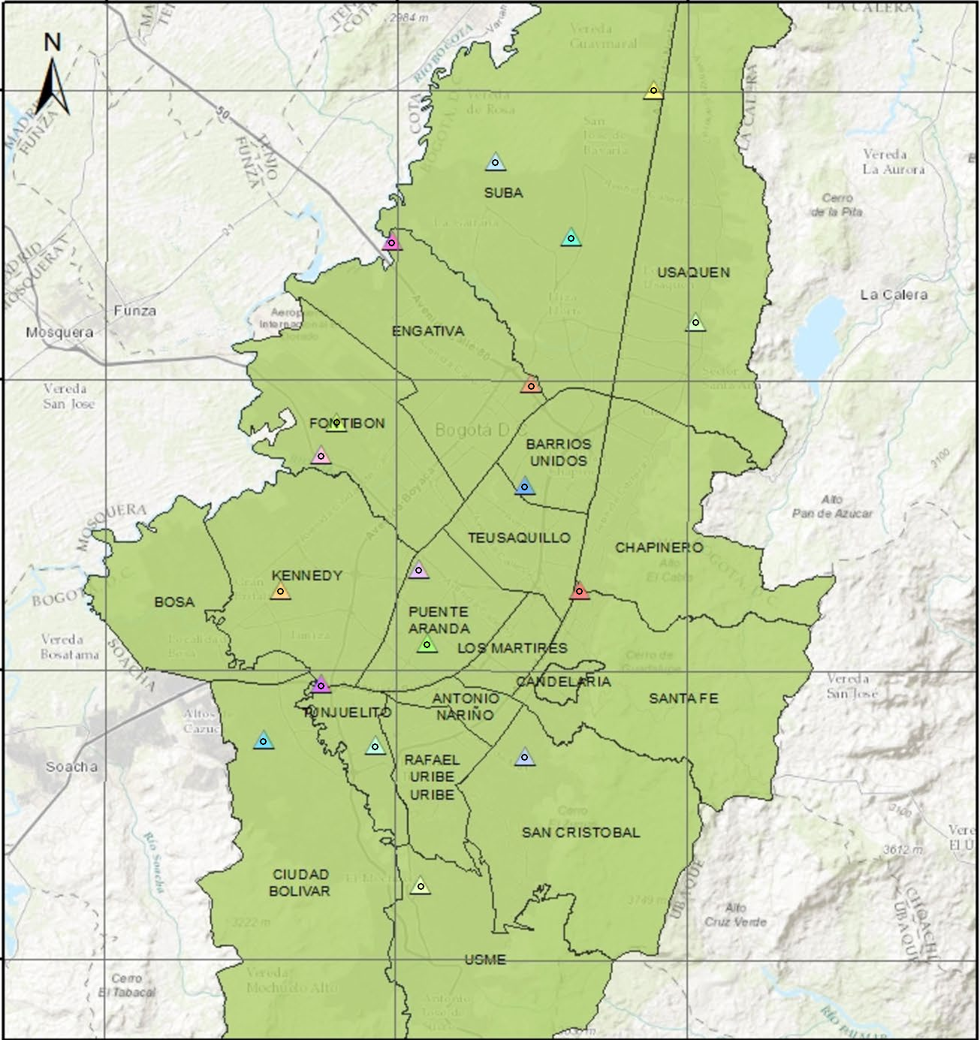

In [5]:
# 3. Overlay for a visual check (rings should sit on the triangles)
ov = img.copy(); dr = ImageDraw.Draw(ov)
for n, (x, y) in centres.items():
    dr.ellipse([x - 4, y - 4, x + 4, y + 4], outline=(0, 0, 0), width=2)
ov.crop((40, 40, 1345, 1425)).resize((980, 1040)).save(REF / "stations_overlay_check.png")
ov.crop((40, 40, 1345, 1425)).resize((980, 1040))

In [6]:
# 4. Coordinates, plus how much each station contributes to our two targets
st = pd.DataFrame([dict(station=n, lat=float(np.polyval([ay, by], y)), lon=float(np.polyval([ax, bx], x)), px_x=x, px_y=y)
                   for n, (x, y) in centres.items()])
st["sisaire_name"] = st.station.map(lambda n: NAME_MAP[n][0]); st["hourly_name"] = st.station.map(lambda n: NAME_MAP[n][1])

# PM2.5 network mean: station-years with >= 75% valid days (SISAIRE daily file), 2014-2025
comp = pd.read_csv(ROOT / "Data/processed/colombia/bogota/bogota_pm25_completeness_by_station_year.csv")
ok = comp[(comp.completeness >= 0.75) & comp.year.between(2014, 2025)].groupby("station").year.agg(["count", "min", "max"])
st["pm25_years_used"] = st.sisaire_name.map(ok["count"]).fillna(0).astype(int)
st["pm25_first_year"] = st.sisaire_name.map(ok["min"]); st["pm25_last_year"] = st.sisaire_name.map(ok["max"])

# O3 (MDA8) network mean: rebuilt exactly as in Scripts/colombia/bogota/04c_o3_mda8_network.ipynb (>= 70% valid MDA8 days per station-year)
from common.qc import chauvenet_outlier_mask, completeness_by_station_year, select_stations_years
raw_o3 = pd.read_csv("/path/to/home/Documents/Postdoc_MSCA-Bridge/USA_Ozone/DATA_ORIGINAL/O3.csv")
raw_o3 = raw_o3.rename(columns={raw_o3.columns[0]: "datetime"})
raw_o3["datetime"] = pd.to_datetime(raw_o3["datetime"], format="%d/%m/%Y %H:%M", errors="coerce"); raw_o3 = raw_o3.dropna(subset=["datetime"])
cols_o3 = [c for c in raw_o3.columns if c != "datetime"]
long = raw_o3.melt(id_vars="datetime", value_vars=cols_o3, var_name="station", value_name="o3"); long["o3"] = pd.to_numeric(long["o3"], errors="coerce")
long.loc[(long.o3 < 0) | (long.o3 > 500), "o3"] = np.nan
long.loc[long.groupby("station")["o3"].transform(lambda s: chauvenet_outlier_mask(s)), "o3"] = np.nan
if long.duplicated(subset=["datetime", "station"], keep=False).any():
    long = long.groupby(["datetime", "station"], as_index=False)["o3"].mean()
wide = long.pivot(index="datetime", columns="station", values="o3").sort_index()
frames = []
for s in cols_o3:
    r8 = wide[s].rolling(window=8, min_periods=6).mean(); nv = r8.notna().resample("D").sum()
    frames.append(r8.resample("D").max().where(nv >= 18).rename(s))
mda8 = pd.concat(frames, axis=1).reset_index().melt(id_vars="datetime", var_name="station", value_name="o3_mda8").rename(columns={"datetime": "date"})
good = select_stations_years(completeness_by_station_year(mda8, value_col="o3_mda8"), threshold=0.70)
# check against the stored network series
mda8["year"] = mda8.date.dt.year; keep = set(zip(good.station, good.year))
net = mda8[[(s, y) in keep for s, y in zip(mda8.station, mda8.year)]].groupby("date")["o3_mda8"].mean().rename("rebuilt")
stored = pd.read_parquet(ROOT / "Data/processed/colombia/bogota/bogota_o3_mda8_daily.parquet").set_index("date")["o3_mda8"]
print("rebuilt O3 network vs stored, max abs difference:", float((stored - net.reindex(stored.index)).abs().max()))
g3 = good.groupby("station").year.agg(["count", "min", "max"])
st["o3_years_used"] = st.hourly_name.map(g3["count"]).fillna(0).astype(int)
st["o3_first_year"] = st.hourly_name.map(g3["min"]); st["o3_last_year"] = st.hourly_name.map(g3["max"])
st["in_pm25_network"] = st.pm25_years_used > 0; st["in_o3_network"] = st.o3_years_used > 0
st = st.sort_values("station").reset_index(drop=True)
st.to_csv(DATA_OUT / "bogota_stations_digitised.csv", index=False)
st[["station", "lat", "lon", "pm25_years_used", "o3_years_used", "in_pm25_network", "in_o3_network"]].round(5)

rebuilt O3 network vs stored, max abs difference: 0.0


,station,lat,lon,pm25_years_used,o3_years_used,in_pm25_network,in_o3_network
0,Bolivia,4.73553,-74.12673,4,1,True,True
1,Carvajal-Sevillana,4.59534,-74.14897,8,7,True,True
2,Centro de alto rendimiento,4.65819,-74.08486,11,6,True,True
3,Ciudad Bolívar,4.57776,-74.16707,5,2,True,True
4,Colina,4.73695,-74.07020,4,1,True,True
5,El Jazmín,4.60841,-74.11550,5,2,True,True
6,Fontibón,4.67874,-74.14400,7,4,True,True
7,Guaymaral,4.78364,-74.04418,11,10,True,True
8,Kennedy,4.62528,-74.16163,12,7,True,True
9,Las Ferias,4.69015,-74.08273,12,8,True,True


**Not on the paper's map, but in our PM2.5 network mean:** the two Mochuelo rural stations
(`BOGOTA RURAL - MOCHUELO`, `MOCHUELO - COLEGIO`) and the mobile unit `MÓVIL 7MA`, which the paper's
figure does not show. `BOSA` never reaches 75% completeness in any year, so it never enters.
`P_CAMI - FONTIBÓN` is assumed to be the RMCAB Fontibón station (probable, to be confirmed).

In [7]:
# Which of our stations have no coordinates?
extra = sorted(set(comp.station) - set(st.sisaire_name))
print("PM2.5 stations without a position on the paper's map:", extra)
print(ok.reindex(extra).dropna())

PM2.5 stations without a position on the paper's map: ['BOGOTA RURAL - MOCHUELO', 'BOSA', 'MOCHUELO - COLEGIO', 'MÓVIL 7MA']
                         count     min     max
station                                       
BOGOTA RURAL - MOCHUELO    9.0  2017.0  2025.0
MOCHUELO - COLEGIO         2.0  2024.0  2025.0
MÓVIL 7MA                  4.0  2020.0  2025.0
